# 05 - Optimization analysis

Iterative optimize -> AC power flow -> correct loop, objective breakdown, BESS sizing, PV hosting capacity and the cost vs peak trade-off.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils.config import load_config
from src.analysis import visualization as viz
viz.apply_style()
config = load_config(ROOT / "config" / "config.yaml")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
pd.read_csv(ROOT / 'results' / 'tables' / 'optimization_iterations.csv')

,iteration,objective_eur,solve_time_s,max_voltage_mismatch_pu,v_min_model_pu,v_min_ac_pu,v_max_ac_pu,ac_undervoltage_bus_steps,ac_overvoltage_bus_steps,trafo_max_pct,line_max_pct,trafo_margin,line_margin,selected,scenario
0,1,8688.370337,7.204986,0.013128,0.939244,0.928294,1.011215,130,0,65.772368,36.506996,1.0,1.0,False,S6_smart_charging
1,2,11292.787428,5.479056,0.002460,0.928294,0.928294,1.011541,130,0,65.772368,36.506996,1.0,1.0,False,S6_smart_charging
2,3,11292.852730,12.278535,0.002018,0.928294,0.928294,1.011192,130,0,65.772368,36.506996,1.0,1.0,False,S6_smart_charging
3,4,11292.836488,10.371393,0.000122,0.928294,0.928294,1.011192,130,0,65.772368,36.506996,1.0,1.0,True,S6_smart_charging
4,1,7618.143506,21.504592,0.012786,0.952000,0.941764,1.010880,45,0,57.640837,31.991026,1.0,1.0,False,S7_smart_bess
5,2,7585.771172,21.987620,0.002063,0.951023,0.950582,1.010681,0,0,58.726959,32.593083,1.0,1.0,False,S7_smart_bess
6,3,7584.321853,15.665294,0.001473,0.950754,0.950800,1.010742,0,0,58.489734,32.461310,1.0,1.0,True,S7_smart_bess


In [3]:
pd.read_csv(ROOT / 'results' / 'tables' / 'optimization_objective.csv').T

,0,1
scenario,S6_smart_charging,S7_smart_bess
solver,appsi_highs:optimal,appsi_highs:optimal
objective_eur,11292.836488,7584.321853
term_energy_cost_eur,7084.955788,6780.688672
term_peak_demand_eur,835.908008,713.193387
term_voltage_violation_eur,3371.972692,10.334531
term_pv_curtailment_eur,0.0,0.0
term_battery_degradation_eur,0.0,80.105263
iterations,4,3
validated,True,True


In [4]:
from src.utils.storage import load_result
from src.models.ev_model import validate_ev_schedule
s7 = load_result('S7_smart_bess')
report = validate_ev_schedule(s7.ev_power_kw, s7.data.fleet, s7.data.dt_h)
print(f"All {len(report)} EVs reach their requirement; minimum final SOC {report.final_soc.min():.3f}")
print(f"BESS SOC range {s7.validation['bess_soc'].min():.3f} - {s7.validation['bess_soc'].max():.3f}")

All 150 EVs reach their requirement; minimum final SOC 0.800

BESS SOC range 0.100 - 0.900

In [5]:
pd.read_csv(ROOT / 'results' / 'tables' / 'experiment_bess.csv')[['bess_capacity_kwh','peak_import_kw','v_min_pu','voltage_violation_bus_steps','total_cost_eur','bess_throughput_kwh']]

,bess_capacity_kwh,peak_import_kw,v_min_pu,voltage_violation_bus_steps,total_cost_eur,bess_throughput_kwh
0,0,2786.360028,0.928294,130,7920.867288,0.000000
1,250,2647.779595,0.938299,109,7817.509254,389.574424
2,500,2518.511228,0.941610,84,7716.769280,801.052632
3,1000,2379.572718,0.950800,0,7574.510920,1602.105263


In [6]:
pd.read_csv(ROOT / 'results' / 'tables' / 'experiment_hosting.csv')[['pv_penetration_pct','control','v_max_pu','trafo_loading_max_pct','pv_curtailment_kwh','voltage_violation_bus_steps']]

,pv_penetration_pct,control,v_max_pu,trafo_loading_max_pct,pv_curtailment_kwh,voltage_violation_bus_steps
0,0,uncontrolled,1.013650,90.097888,0.000000,712
1,0,optimized,1.014435,73.258979,0.000000,385
2,50,uncontrolled,1.013650,83.207487,0.000000,243
3,50,optimized,1.014436,61.433692,0.000000,0
4,100,uncontrolled,1.013650,79.887057,0.000000,166
5,100,optimized,1.014693,58.554575,0.000000,0
6,150,uncontrolled,1.013650,79.530095,0.000000,142
7,150,optimized,1.010742,58.489734,0.000000,0
8,200,uncontrolled,1.026403,79.173623,0.000000,121
9,200,optimized,1.026403,71.547709,0.000000,0


In [7]:
pd.read_csv(ROOT / 'results' / 'tables' / 'experiment_tradeoff.csv')[['peak_charge_eur_per_kw','peak_import_kw','energy_cost_eur','total_cost_eur']]

,peak_charge_eur_per_kw,peak_import_kw,energy_cost_eur,total_cost_eur
0,0.0,2647.126931,6776.085907,7650.329250
1,0.1,2393.016555,6780.343089,7578.353318
2,0.3,2379.572718,6780.533842,7574.510920
3,0.6,2391.401444,6779.982572,7577.508268
4,1.0,2360.402583,6781.990606,7570.216644
5,2.0,2354.906371,6782.562992,7569.140166
6,4.0,2329.838935,6783.384107,7562.441051


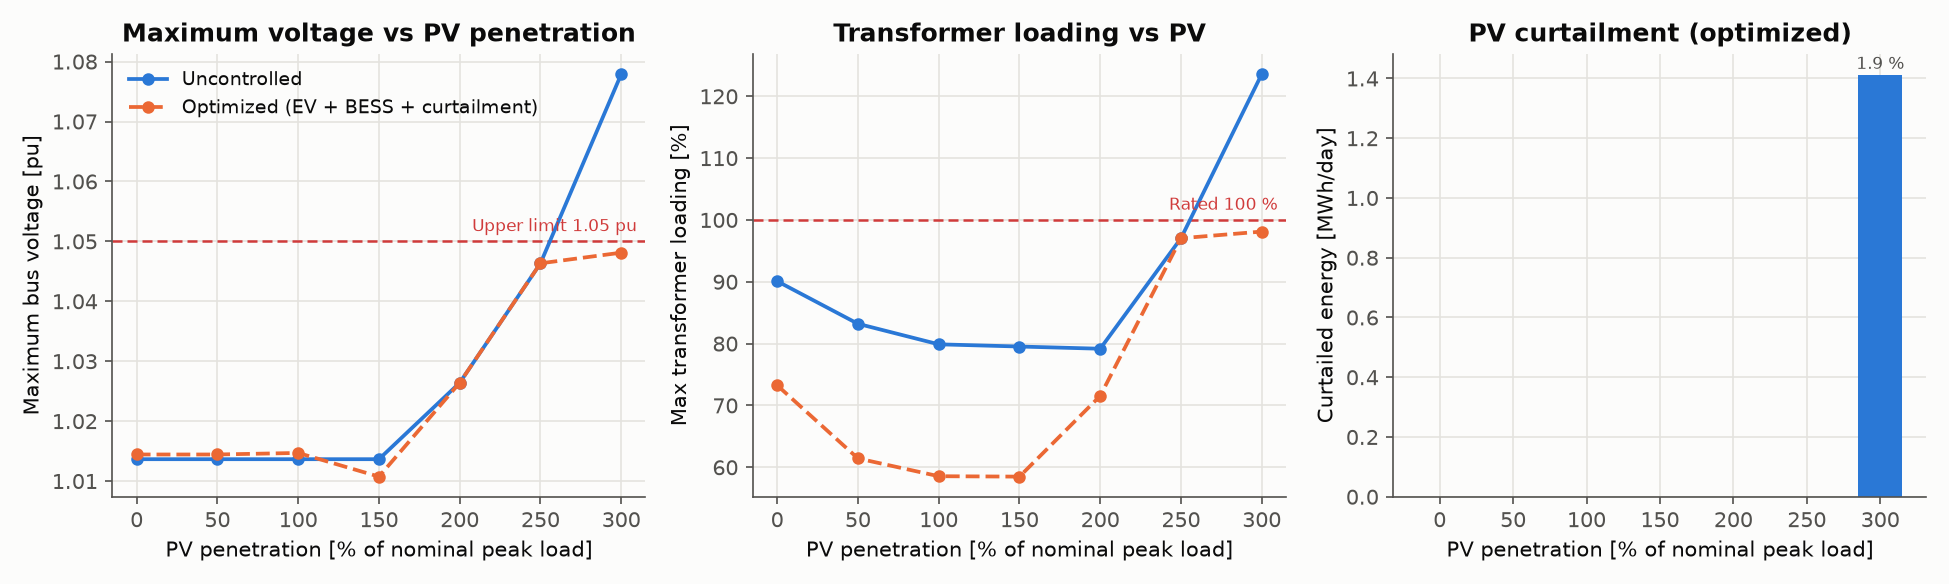

In [8]:
from IPython.display import Image
Image(filename=str(ROOT / 'results' / 'figures' / '09_pv_curtailment.png'))

### OLTC setpoint sensitivity
Remaining undervoltage in S1/S4/S6 is largely set by where the substation regulator holds the MV busbar (lower deadband edge 0.995 pu at the evening peak).

In [9]:
pd.read_csv(ROOT / 'results' / 'tables' / 'experiment_oltc.csv')[['oltc_band','scenario','busbar_v_min_pu','v_min_pu','v_max_pu','voltage_violation_bus_steps','losses_kwh']]

,oltc_band,scenario,busbar_v_min_pu,v_min_pu,v_max_pu,voltage_violation_bus_steps,losses_kwh
0,0.995-1.015,S1_baseline,0.996544,0.932949,1.014487,540,2283.514068
1,0.995-1.015,S4_pv_ev,0.995005,0.923760,1.013650,142,1442.976370
2,0.995-1.015,S6_smart_charging,0.995036,0.928294,1.011192,130,1399.611247
3,0.995-1.015,S7_smart_bess,0.995036,0.950800,1.010742,0,1419.313671
4,1.015-1.035,S1_baseline,1.016248,0.948314,1.034924,15,2218.006882
5,1.015-1.035,S4_pv_ev,1.016134,0.939300,1.034680,40,1393.830928
6,1.015-1.035,S6_smart_charging,1.016134,0.958268,1.034924,0,1344.383115
7,1.015-1.035,S7_smart_bess,1.016645,0.951827,1.036348,0,1375.520069
